# 05-串口OTA升级：两种模式的完整实现


## 1. 本篇内容与实验目标

前两篇已经完成“用 Ymodem 接收固件并写入 Flash”和“由 Bootloader 跳转启动 App”。本篇补上控制流程：**什么时候进入升级？升级请求怎样跨越一次复位？App 已经无法运行时，又怎样重新下载固件？**

对应讲义 `OTA远程升级.pdf` 第 **48—53 页**（PDF 物理页码）和以下五段视频。

| 视频 | 播放器显示时长 | 本篇重点 |
|---|---|---|
| `17_串口OTA_升级模式介绍.mp4` | 6:38 | App 主导与 Bootloader 主导两种触发方式 |
| `18_串口OTA_升级模式一实现.mp4` | 19:33 | 升级标志、复位、分区统一、v1.0 → v1.4 验证 |
| `19_串口OTA_升级模式二实现_倒计时显示.mp4` | 12:34 | SysTick 计时、减少日志、原地刷新倒计时 |
| `20_串口OTA_升级模式二实现_显示菜单及升级.mp4` | 10:13 | 中止倒计时、菜单、下载与错误固件恢复 |
| `21_串口OTA_总结与互动.mp4` | 3:43 | 代码关系、两种模式的应用场景 |

资料来自[课程百度网盘](https://pan.baidu.com/s/19vzB65qjPtH6BEy0EBZ5VQ?pwd=1234)，提取码 `1234`。本篇已核对上述视频的完整自动中文字幕、对应讲义原图及配套源码，技术名词与函数名以源码为准。实验平台为 **GD32F407VET6，512 KB 片上 Flash**；本机完成资料与文件静态检查，未连接开发板进行 Keil 编译、烧录或硬件测试。

阅读顺序：先看两种触发方式和统一分区，再实现 App 触发，最后添加 Bootloader 倒计时与菜单。协议帧格式、Flash 驱动与跳转底层细节分别参照第02—04篇。


## 2. 把已有模块串成一次完整升级

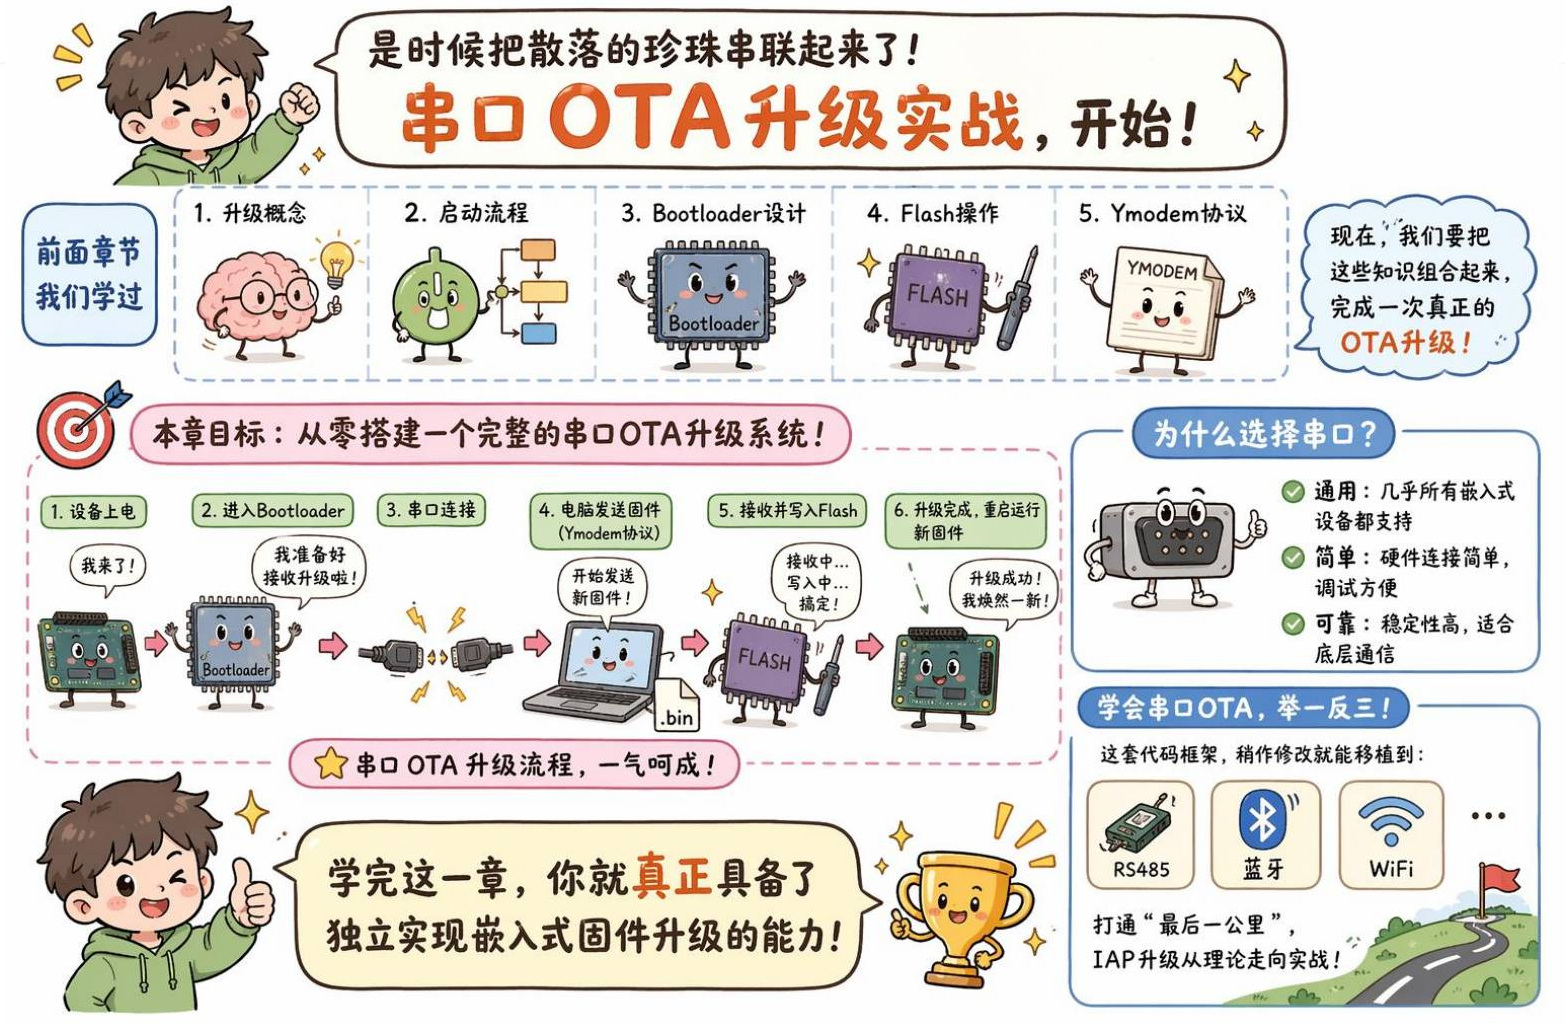

*讲义第49页：将升级概念、启动流程、Bootloader、Flash 和 Ymodem 串成完整系统。*

本篇的主体不是重新实现传输协议，而是把三个已有能力调度起来：

| 已有模块 | 本篇怎样调用 | 解决的问题 |
|---|---|---|
| `store_app.c` 与 Flash 驱动 | 写、读、擦除参数区的升级标志 | App 与 Bootloader 跨复位传递升级请求 |
| `update.c` | `UpdateApp()` → `YmodemReceive()` | 等待上位机发送 bin，接收并写入 App 区 |
| Bootloader 的启动函数 | `BootToApp()` | 将控制权交给 App |

完整链路可以概括为：

```text
确定升级入口 → 进入 Bootloader 的接收流程
→ 上位机用 Ymodem 发送正确链接的 App.bin
→ 接收并写入 App 分区 → 处理升级结果和标志
→ 跳转到 App → 观察新版本持续运行
```

课程先使用串口，是因为接口普遍、连接与调试直观。后续换成 RS485、蓝牙或 Wi-Fi 时，仍可保留“触发、接收、写入、启动”的职责划分，再适配通信与下载方式。这里的“串口 OTA”沿用课程命名，当前实操通过有线串口完成 IAP 升级。


## 3. 两种模式：日常升级入口与本地恢复入口

| 对比项 | 模式一：App 触发 | 模式二：Bootloader 菜单触发 |
|---|---|---|
| 谁先接收请求 | 正在运行的 App | 复位后先运行的 Bootloader |
| 如何进入升级 | App 收到命令 → 写标志 → 复位 | 开机倒计时内收到串口字节 → 菜单选 `1` |
| 是否依赖 App 正常运行 | 依赖，App 必须能接收命令并复位 | 不依赖 App，但 Bootloader 和通信链路必须可用 |
| 是否用到升级标志 | 使用参数区 `0xABCD` 标志跨越复位 | 直接从菜单升级时不必先写标志 |
| 正常启动行为 | 没有标志时直接启动 App（Bootloader3） | 倒计时未被中止则启动 App（Bootloader4） |
| 主要优势 | 便于自动化、批量操作，用户感知较少 | App 出错时仍可重新下载正常固件 |
| 主要限制 | App 死机后可能无法响应升级请求 | 本课需要本地串口连接，并在窗口期内操作 |
| 讲义中的典型场景 | 智能家居、扫地机器人定期静默更新 | 工业现场调试、售后本地恢复 |

两种模式可以共存：**模式一承担常规升级，模式二保留独立于 App 的维护入口。** 模式二能恢复 App 故障的前提是 Bootloader 没有被破坏，不应把它理解为任何故障都能恢复。

讲义用“特定串口命令或物理按键长按”解释模式二的可选触发方式；本课最终代码采用的是**收到任意串口字节**。物理按键长按不在这版工程中实现。


## 4. 先统一 Flash 分区与工程配置

新增升级参数后，App 需要给参数区让出一个完整扇区。课程及配套 Bootloader3、Bootloader4、App 工程使用以下布局：

| 区域 | 扇区 | 起始地址 | 结束地址（包含） | 大小 |
|---|---|---|---|---|
| Bootloader | Sector 0 | `0x08000000` | `0x08003FFF` | 16 KB |
| 参数区 Parameter | Sector 1 | `0x08004000` | `0x08007FFF` | 16 KB |
| App | Sector 2—7 | `0x08008000` | `0x0807FFFF` | 480 KB |

`Common/store_app.h` 中的核心宏如下，省略了原文件中同值重复出现的标志宏与注释：

```c
#define FLASH_SIZE                 0x80000
#define BOOTLOADER_SIZE            (16 * 1024)
#define PARAMETER_SIZE             (16 * 1024)

#define PARAM_ADDR_IN_FLASH        (0x08000000 + BOOTLOADER_SIZE)
#define APP_ADDR_IN_FLASH          (0x08000000 + BOOTLOADER_SIZE + PARAMETER_SIZE)
#define NEED_UPDATE_VERSION_FLAG   0xABCD
#define VECTOR_OFFSET              (BOOTLOADER_SIZE + PARAMETER_SIZE)
```

`Common/update.h` 引入 `store_app.h`，并按统一分区计算容量：

```c
#include "store_app.h"
#define FLASH_APP_SIZE (FLASH_SIZE - (BOOTLOADER_SIZE + PARAMETER_SIZE))
// 0x80000 - 0x4000 - 0x4000 = 0x78000，即 480 KB
```

需要同时核对四处：**App 链接基址、固件接收写入地址、Bootloader 跳转地址、中断向量表偏移**。前三者对应 `0x08008000`，最后一项是相对 Flash 基址的偏移 `0x8000`。

Keil 的 App `IROM1 Start` 应为 `0x08008000`。代码包中的 Start 已正确，但 `Size` 仍为 `0x80000`；针对本课512 KB芯片，实际可用 Size 应设置为 **`0x78000`**。Bootloader 的 Start 为 `0x08000000`、Size 为 `0x4000`，添加菜单后也应确认链接结果没有超出16 KB。

不要沿用上一阶段无参数区演示中的 `0x08004000` App 起点。代码包个别跳转注释仍留着旧地址，判断时以实际宏和链接配置为准。


## 5. 模式一的完整时序：App 写标志，Bootloader 执行升级

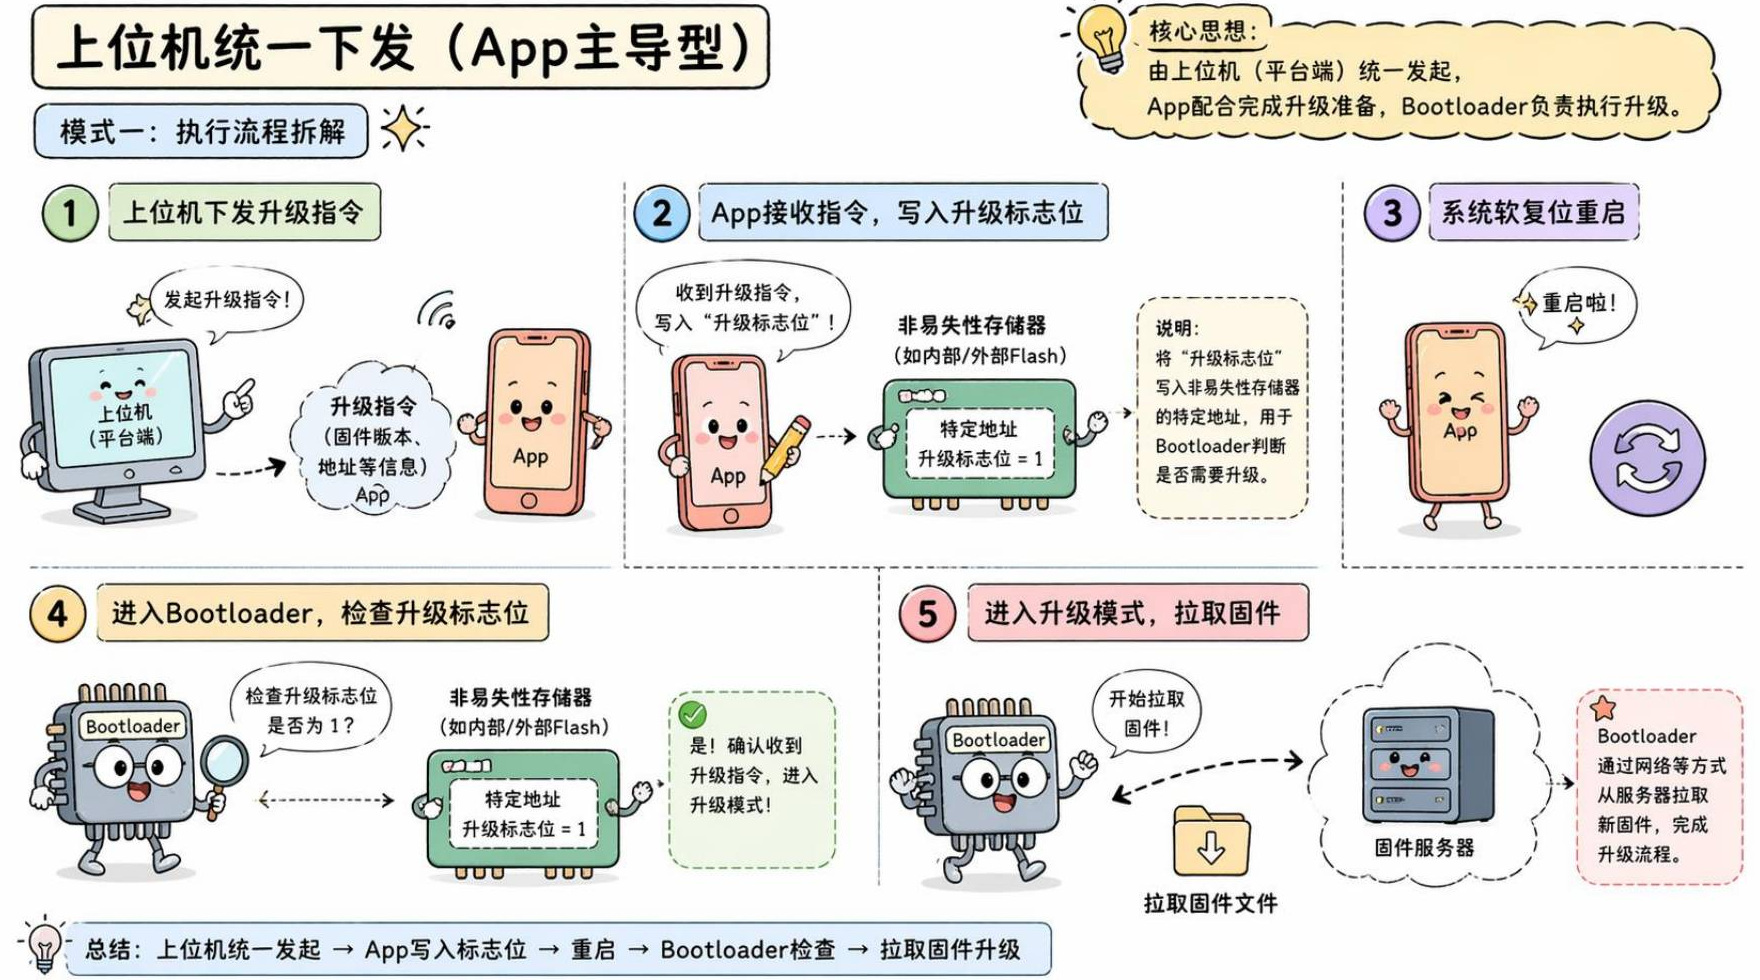

*讲义第50页的通用流程。图中的“标志位=1”表示逻辑状态，代码实际用一个半字 `0xABCD`；图中的网络服务器在本篇实操中对应串口上位机。*

```text
App 正常运行
  └─ USART0 收到 U / u
       ├─ 在 0x08004000 写入半字 0xABCD
       └─ NVIC_SystemReset() 系统复位
            └─ 从 Flash 启动入口重新运行 Bootloader
                 ├─ 读参数区，发现 0xABCD
                 ├─ UpdateApp()：等待 Ymodem 固件并写入 App 区
                 ├─ ClearUpdateVerFlag()：擦除升级标志
                 ├─ 延时100 ms（课堂处理）
                 └─ BootToApp()：启动新 App
```

为什么不只用一个普通全局变量？因为 App 和 Bootloader 是分别链接的固件，系统复位后又会重新初始化运行环境；普通 RAM 变量不能直接作为两份固件约定好的、可跨掉电保留的请求。这里让双方按同一地址、同一数据类型、同一约定值访问非易失的 Flash 参数区。

本课用 `U/u` 简化升级命令，只检查接收数据的首字节。讲义中的版本号、下载地址等是通用方案示意，这版串口命令并没有携带或解析这些字段。


## 6. 参数标志的三个函数：写入、检查与清理

`Common/store_app.c` 在 App、Bootloader3 和 Bootloader4 中的实现一致。先看 App 写标志的函数：

```c
bool SetUpdateVerFlag(void){
    uint16_t update_flag = NEED_UPDATE_VERSION_FLAG;
    uint16_t read_back = 0xFFFF;

    // 先擦除参数区域
    if (!FlashErase(PARAM_ADDR_IN_FLASH, sizeof(update_flag))) {
        return false;
    }
    // 写入需要升级标志位
    if (!FlashWrite16bit(PARAM_ADDR_IN_FLASH, &update_flag, 1)) {
        return false;
    }
    // 检查是否写入成功
    if (!FlashRead(PARAM_ADDR_IN_FLASH, (uint8_t *)&read_back, sizeof(read_back))) {
        return false;
    }

    return (read_back == NEED_UPDATE_VERSION_FLAG);
}
```

操作顺序为 **擦除 → 写一个半字 → 读回确认**。`FlashWrite16bit(..., 1)` 中的 `1` 是半字个数，不是一个字节；`uint16_t` 的大小为2字节。本课芯片按小端存放，查看两个原始字节时应看到 `CD AB`，按16位值查看则是 `0xABCD`。

Bootloader 检查并清理标志：

```c
bool CheckNeedUpdate(void){
    uint16_t update_flag = 0xFFFF;

    // 读取需要升级标志位
    if (!FlashRead(PARAM_ADDR_IN_FLASH, (uint8_t *)&update_flag, sizeof(update_flag))) {
        return false;
    }

    return (update_flag == NEED_UPDATE_VERSION_FLAG);
}

void ClearUpdateVerFlag(void){
    // 擦除参数区域
    (void)FlashErase(PARAM_ADDR_IN_FLASH, sizeof(uint16_t));
}
```

擦除后的 Flash 数据为全1，因此读出的半字一般为 `0xFFFF`；“清标志”并不是写入 `0x0000`。注意 `FlashErase(..., sizeof(uint16_t))` 虽然传入长度为2，驱动仍按所在扇区擦除，实际会清掉整个 **16 KB 参数扇区**。如果将来同一扇区还放其他配置，就必须处理配置保存与恢复，不能把它当作只擦两个字节。

当前 `ClearUpdateVerFlag()` 丢弃了擦除返回值，`CheckNeedUpdate()` 在读取失败时也返回 false；课堂实现并没有区分“明确没有请求”和“参数读取失败”。


## 7. App 接收命令并复位到 Bootloader

App 的 `User/main.c` 在串口接收回调中识别命令：

```c
void USART0_on_recv(uint8_t* data, uint32_t len) {
    printf("recv[%d]:%s\n", len, data);
    
    if(data[0] == 'U' || data[0] == 'u'){  
        // 添加升级标记
        SetUpdateVerFlag();
        
        // 停机, 重启进入升级流程
        iap_reset_to_boot();
    }
}
```

调用的复位函数位于 `Common/iap_driver.c`：

```c
void iap_reset_to_boot(void) {
  // 关闭所有中断
  __disable_irq();
  // 系统复位函数
  NVIC_SystemReset();
}
```

`NVIC_SystemReset()` 发起系统复位；在本课启动配置下，复位后会从 Flash 起始的 Bootloader 运行，再由它检查升级标志。这里不需要 App 用函数指针跳回 Bootloader。

App 自己启动时仍要处理向量表偏移，以下函数在 App 的 `main()` 开头调用：

```c
void iap_init_irq(void) {
  // 设置中断向量表起始地址偏移量
  nvic_vector_table_set(NVIC_VECTTAB_FLASH, VECTOR_OFFSET);
  // 启用中断
  __enable_irq();
}
```

**复位入口与 App 的中断向量表重定位是两件事。** 前者让处理器重新进入 Bootloader；后者保证 App 运行期间的中断到达位于 `0x08008000` 的 App 向量表。跳转交接的限制继续参照第04篇。

工程补充：课堂回调直接写 Flash 并复位，没有检查 `SetUpdateVerFlag()` 的返回值。实际实现至少应确认 `len > 0`、写标志成功后再复位；这份驱动在接收中断中调用回调，也可以改为回调只记录请求、由主循环处理 Flash 与复位。不要在没有结束符保证的任意数据上直接使用 `%s`。


## 8. Bootloader3：检查标志后决定升级或启动

模式一主要对应 `03_GD32F407_IAP_Bootloader3/User/main.c`。在中断分组、SysTick、延时、串口和 GPIO 初始化之后，主流程摘录如下：

```c
if (CheckNeedUpdate()) {
    UpdateApp();
    ClearUpdateVerFlag();
    DelayNms(100);
}

BootToApp();
```

没有升级请求时不进入 `UpdateApp()`，直接启动现有 App；有请求时，先等待并接收固件，再清标志、延时并尝试启动。课程解释清标志的目的是：避免下次重启时仍然重复进入同一个升级请求。

需要准确理解课堂代码：**`UpdateApp()` 返回后就清标志并尝试启动，它并不是“只在确认升级成功后清标志”。** 后面会看到这个函数返回类型是 `void`，因此调用者没有得到升级结果。

工程组装时应把 `store_app.c` 加到 Keil 的源文件分组中，并正确配置头文件搜索路径。只把 `.c/.h` 放进目录或只写 `#include`，不等于实现文件已经参与链接。第18节约05:00处专门处理了文件未加入工程的问题。


## 9. 共用的升级入口：UpdateApp 做了什么

Bootloader4 的 `Common/update.c` 中，入口完整代码如下；Bootloader3 同名函数的逻辑相同，等待提示的换行写法不同。

```c
void UpdateApp(){
    int32_t imageSize = 0;

    // 阻塞式循环下载新版本固件
    printf("等待文件传输...(按下字母'a'中断传输abort)\r\n");

    // 通过Ymodem协议接收固件并烧录
    imageSize = YmodemReceive();
    
    // 需要等待一会儿, 否则SecureCRT不能正常显示如下日志
    DelayNms(100);
    
    if(imageSize > 0) {
        printf("烧录成功[ Name: %s ,imageSize: %d Bytes]\r\n", g_imageName, imageSize);
    } else if (imageSize == -1) {
        printf("固件过大，超出可用空间，无法下载\r\n");
    } else if (imageSize == -2) {
        printf("固件校验失败\r\n");
    } else if (imageSize == -3) {
        printf("用户主动中断发送\r\n"); // Ctrl + C
    } else if (imageSize == -4) {
        printf("用户主动取消abort\r\n"); // a A
    } else {
        printf("接收文件失败code: %d \r\n", imageSize);
    }

}
```

`YmodemReceive()` 才负责接收与写入，`UpdateApp()` 包装了等待提示、延时和结果日志。接收起点为 `APP_ADDR_IN_FLASH`，文件大小上限使用 `FLASH_APP_SIZE`。

| 返回／分支 | 资料中对应的含义 | 阅读源码时的边界 |
|---|---|---|
| `imageSize > 0` | 接收流程返回文件大小，打印“烧录成功” | 不是独立的整包固件有效性证明 |
| `-1` | 文件声明大小超过 App 可用空间 | 接收端发送取消控制字节 |
| `-3` | 收到取消序列，打印主动中断 | 按接收代码的双 `CA` 路径处理 |
| `-4` | 接收包头阶段收到 `A/a`，主动退出 | 课堂用于取消等待或传输流程 |
| `-2` | 日志预留的“固件校验失败”分支 | 不能仅凭此分支断言已有整包校验；该接收函数中未找到返回 `-2` 的路径 |

包的 CRC16 错误在 `RecevicePacket()` 中返回错误，再由接收循环请求重传；这和“整个 App 镜像已验证可启动”不同。课堂接收流程没有把擦写失败逐层上报，也没有做完整固件签名或整包哈希校验。

第18、20节在下载后启动前增加了 `DelayNms(100)`；`UpdateApp()` 内还为 SecureCRT 显示日志保留了100 ms。复现时可以保留课堂时序，**固定延时不能替代检查 Flash 完成状态、返回值和读回数据**，也不能据此保证任意硬件上都能正常启动。


## 10. 模式一实操：从 v1.0 升级到 v1.4

以下按课堂流程整理，可用 SecureCRT 的 `Transfer → Send Ymodem` 完成单板验证。

1. **准备两个 App 版本。** 保留能持续输出 `App run v1.0` 的旧版本；修改初始化与循环中的版本日志，重新编译生成 v1.4 的 bin。两版都要按 `0x08008000` 链接，向量表偏移均为 `0x8000`。
2. **保存新固件。** 将新生成的 `Project/Objects/GD32F407.bin` 复制到版本目录并改为容易区分的名称，例如 `v1.4.bin`。这是整理文件名，不是通过改后缀转换格式。确认复制的是本次构建产物。
3. **烧入初始系统。** 通过调试器准备 Bootloader3 和旧版 App。下载设置应只擦除相应区域，避免后烧的工程全片擦除了另一份固件。复位后应由 Bootloader 启动旧版 App。
4. **连接升级串口。** USART0 为 PA9/TX、PA10/RX，参数为 **115200、8数据位、无校验、1停止位**。USB转串口与开发板TX/RX交叉并共地；COM号按本机实际选择。当前驱动不启用硬件流控，终端使用无流控。
5. **触发请求。** 在 App 正常运行时向 USART0 发送 ASCII `u` 或 `U`。App 写标志后复位，应再次看到 Bootloader 标识与“等待文件传输”提示。
6. **发送固件。** 在 SecureCRT 中选择 `Transfer → Send Ymodem`，选中准备好的 v1.4 bin，开始传输。不要用粘贴二进制文本或普通“发送文件”替代 Ymodem。
7. **观察完成。** 课堂最终演示中，传输结束后启动到 v1.4，持续输出新版本运行日志。再按硬件复位，新版本仍可正常启动，不再重复等待此次升级。

```text
课堂最终效果示意（省略地址、计数和中间协议输出）

App run v1.0 -> ...
  [发送 u]
Bootloader------------------
等待文件传输...
  [Send Ymodem：v1.4.bin]
烧录成功[ Name: ... ,imageSize: ... Bytes]
App Init v1.4
App run v1.4 -> ...
```

版本号在课堂中用日志区别前后固件，不代表接收端会按文件名检查版本、阻止降级或校验硬件型号。代码包附带的 App 源码仍打印 v1.0；要复现新版本输出，需要自行修改并重新生成对应 bin。


## 11. 第18节的三次排查：不要只看“传完了”

| 课堂位置 | 问题与现象 | 最终处理与应记住的检查点 |
|---|---|---|
| 约09:10—10:45 | 加入参数区后，旧 App 仍按原地址生成，启动时栈地址不合法或无法运行 | App 起点改为 `0x08008000`，同时核对 `VECTOR_OFFSET = 0x8000`，重新生成新固件 |
| 约12:10—14:40 | 传输／写入不符合预期，编译存在宏重定义警告 | 清理 `update.h` 等处的旧分区宏，通过 `store_app.h` 统一地址与总容量，用 `FLASH_APP_SIZE` 计算可用空间 |
| 约16:40—18:45 | 接收后启动或终端日志表现不稳定 | 课堂增加下载后的100 ms延时，再验证 v1.0 → v1.4 与硬件复位后的运行 |

排查时不要把“Ymodem 对话框结束”当作全部验收。至少分开确认：

```text
新 bin 是否正确生成
→ 接收目标是否为 0x08008000
→ Flash 中向量表和数据是否合理
→ Bootloader 是否走到正确跳转入口
→ App 是否持续运行，中断和版本日志是否正常
```

课程还提醒注意文件名长度和编译警告。代码中的文件名缓冲区有固定上限，不应认为任意长度文件名都能安全解析；实验先使用简短、容易识别的名称。编译警告应结合具体位置处理，不要依赖“最后包含哪个头文件就用哪个地址”。


## 12. 模式二的时序：倒计时内中止启动，进入维护菜单

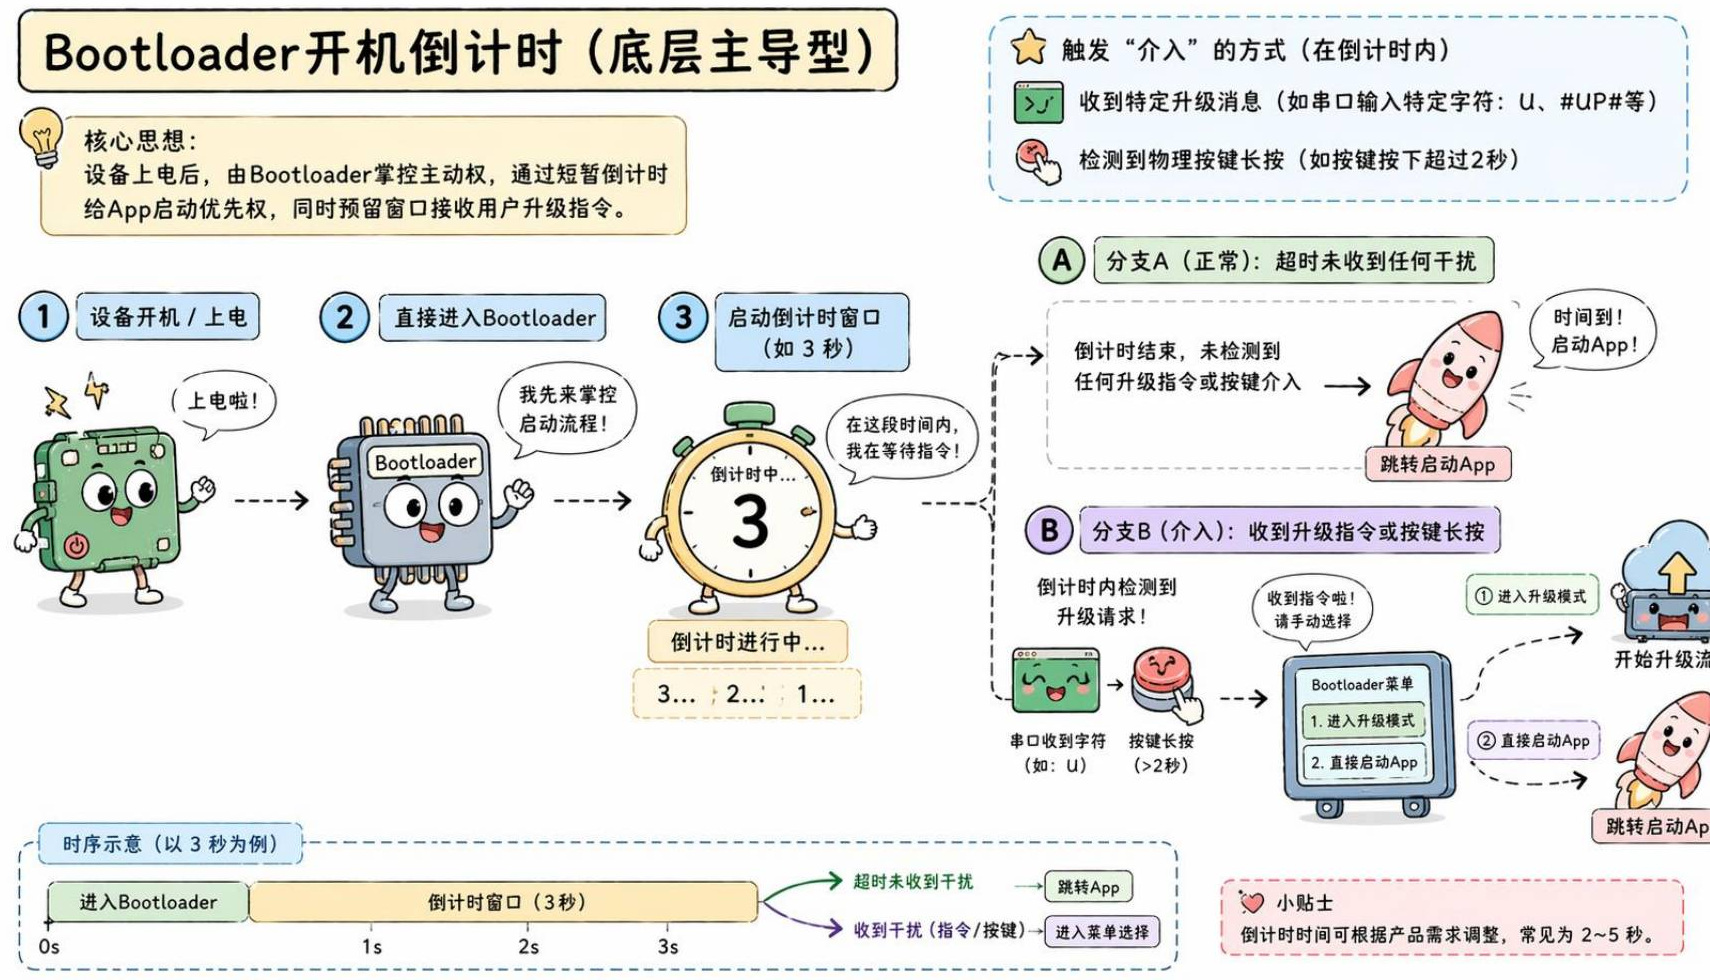

*讲义第51页以3秒和按键长按等方式说明通用方案；本课配套 Bootloader4 最终设置为5000 ms，并使用串口任意字节中止倒计时。*

```text
设备上电／复位 → 先运行 Bootloader
  └─ 显示倒计时，循环检查时间和串口
       ├─ 超时且未中止 → BootToApp()
       └─ 收到任意串口字节 → 停止倒计时，显示 Main Menu
            ├─ 再输入字符 '1' → UpdateApp() → 延时 → 尝试启动 App
            ├─ 再输入字符 '2' → 直接尝试启动 App
            └─ 其他字符 → 继续显示菜单，等待下一次输入
```

这里“按任意键”指在串口终端键盘上操作，由终端把字节发到开发板，不是程序已经实现了板载按键检测。

**打断倒计时的字节已经被读取。** 例如先按 `f` 进入菜单，再按 `1` 选择下载；如果在倒计时阶段直接按一次 `1`，它首先用于停止倒计时，仍需在菜单中再次输入 `1`。按键对应的是 ASCII 字符 `'1'`、`'2'`，不是数值 `0x01`、`0x02`。


## 13. 获取毫秒计数：用 SysTick 支撑倒计时

Bootloader4 的 `User/systick.c` 增加了系统计数：

```c
volatile static uint64_t tick;
```

关键函数如下，来自配套源码：

```c
void systick_config(void)
{
    tick = 0;
    /* setup systick timer for 1000Hz interrupts */
    if(SysTick_Config(SystemCoreClock / 1000U)) {
        /* capture error */
        while(1) {
        }
    }
    /* configure the systick handler priority */
    NVIC_SetPriority(SysTick_IRQn, 0x00U);
}

uint64_t systick_get_tick(){
  return tick;
}

void delay_decrement(void)
{
    tick++;
  
    if(0U != delay) {
        delay--;
    }
}
```

`SysTick_Config(SystemCoreClock / 1000U)` 配置1000 Hz中断，因此每次计数代表1 ms。`User/gd32f4xx_it.c` 的 `SysTick_Handler()` 调用 `delay_decrement()`，在维护延时计数时也让 `tick++`。

`systick_get_tick()` 读到的是**从本次 SysTick 初始化以来的累计毫秒数**，不是已经自动归零的“菜单已等待时间”。本课使用该累计计数实现开机窗口，后文会说明复用到其他时刻时要注意的差异。

`volatile` 提醒编译器该变量可能被中断修改；它本身不保证32位内核读64位变量的原子性。这里记录课堂实现即可，长期运行的工程应结合计数宽度和并发访问处理。


## 14. 倒计时显示：只在秒值变化时原地打印

第19节先打印递增秒值，再改为剩余秒数，最后增加原地刷新。核心逻辑如下（摘录并整理了缩进）：

```c
#define BOOT_DELAY_COUNT 5000

uint64_t timCount = systick_get_tick();
uint16_t bootDelayNow = 0, bootDelayLast = 0;

// 循环中不断获取最新时间
timCount = systick_get_tick();
bootDelayNow = (BOOT_DELAY_COUNT - timCount) / 1000;

if (bootDelayNow != bootDelayLast) {
    printf("\b\b%2d", bootDelayNow);
    bootDelayLast = bootDelayNow;
}
```

三个实现要点：

1. **时间单位统一。** 最大等待时间和 `timCount` 都用毫秒，减法完成后再除以1000得到显示秒数。
2. **只在值改变时输出。** 循环可以持续检查串口，但无需每次都打印。打印后必须更新 `bootDelayLast`；课堂中漏掉这一步时，同一个数字仍然反复输出。
3. **退回两个字符位置后覆盖。** `\b\b` 让支持终端控制字符的客户端回退两个位置，`%2d` 以至少两列显示数字。退格本身不一定擦除字符，后面的空格与数字才覆盖旧内容。

课程调试时试过8秒、15秒等值，最终代码宏是5000 ms。由于整数除法向下取整，而且初始化也会消耗时间，显示可能先出现 `4`，不能据此断言等待时间一定只有4秒。

`\r` 是回到行首，`\n` 是换行。第20节把提示改成 `\r\n`，避免在终端中只换行而不回到行首形成阶梯状输出；它们和用于覆盖倒计时的 `\b` 用途不同。


## 15. 非阻塞读一个字节，再区分两种退出原因

Bootloader4 的 `Library/USART/USART0.c` 提供非阻塞读取：

```c
bool USART0_RecviveByte(uint8_t* dat){
    if(usart_flag_get(USART0, USART_FLAG_RBNE)){    
        *dat = usart_data_receive(USART0);        
        return true;
    }
    return false;
}
```

函数名 `Recvive` 是课程源码中的拼写。缓冲区有数据时读取一个字节、写入 `serialKey` 并返回 true；没有数据则立即返回 false。函数本身并不会一直等待。

倒计时继续条件是：

```c
while (timCount < BOOT_DELAY_COUNT && !USART0_RecviveByte(&serialKey)) {
    // 更新时钟与倒计时显示
}
```

即“时间未到，并且没有接收到字节”。超时或收到字节任一条件成立，循环就会退出。之后用时间是否达到阈值决定尝试启动，或进入菜单。菜单里的写法：

```c
while (!USART0_RecviveByte(&serialKey));
```

则是利用空循环反复调用非阻塞函数，组合成**忙等输入**。两处用的是同一个函数，外层控制流程不同。

Bootloader 的 `USART_config.h` 配置 `USART0_RX_INT = 0`、`USART0_RX_DMA_ENABLE = 0`，由主循环轮询读取串口。App 的串口实现则使用接收中断与回调。不要在 Bootloader 轮询接收的同时又让另一个中断处理程序抢先读取同一寄存器，否则菜单或 Ymodem 可能收不到预期字节。


## 16. Bootloader4 的完整菜单函数

下面保留 `03_GD32F407_IAP_Bootloader4/User/main.c` 中的完整函数，便于把倒计时、菜单选择和升级调用连起来理解。其前面定义 `BOOT_DELAY_COUNT = 5000`。

```c
void main_menu_cmd(){
    printf("按下任意键, 停止自启动:   ");

    // 获取当前系统时间戳(ms)
    uint64_t timCount = systick_get_tick();
    
    uint16_t bootDelayNow = 0, bootDelayLast = 0;
    
    uint8_t serialKey = 0x00;
    
    // 在限定时间内循环判断是否收到中断消息(可以是串口, 用户按键)
    // 1. 没有到结束时间
    // 2. 没有收到串口消息
    while(timCount < BOOT_DELAY_COUNT && !USART0_RecviveByte(&serialKey)){
        // 获取最新的时间戳
        timCount = systick_get_tick();
        
        // 将毫秒值转换成秒
        bootDelayNow = (BOOT_DELAY_COUNT - timCount) / 1000;
        
        if(bootDelayNow != bootDelayLast){
            printf("\b\b%2d", bootDelayNow);     

            // 记录最新的启动时间
            bootDelayLast = bootDelayNow;
        }
        
    }
    
    // 超时结束, 启动App
    if(timCount >= BOOT_DELAY_COUNT){
        printf("\r\n启动到App\r\n");
        BootToApp();
    }
    
    // 用户按下按键(串口收到消息), 显示菜单
    printf("\r\n显示菜单 -> %c 0x%2X\r\n", serialKey, serialKey); 
    
    while(1){
            // 用户提前结束倒计时显示菜单
        printf("\r\n\n======================= Main Menu ============================\r\n\n");
        printf("************[1].下载固件到Flash*************\r\n\n");
        printf("************[2].启动App*********************\r\n\n");
        printf("==============================================================\r\n\n");
        
        // 阻塞式等待用户输入
        while(!USART0_RecviveByte(&serialKey));
        printf("\r\n Input -> %c 0x%2X\r\n", serialKey, serialKey); 
        
        if(serialKey == '1'){
            printf("下载固件\r\n");
            UpdateApp();
            DelayNms(100);
            BootToApp();
        }
        if(serialKey == '2'){
            printf("启动到App\r\n");
            BootToApp();
        }
        
    }
    
}
```

几个容易漏看的行为：

- 倒计时一旦被中止，内层菜单没有再设置自动退出时间，会等待后续输入。
- 收到其他字符时不执行下载或启动，循环再次打印菜单。
- 配套代码的选项 `1` 已经包含 `BootToApp()`，即接收流程返回后自动尝试启动。第20节约07:15处曾演示先停留菜单、再按 `2` 手动启动，后续才加入自动启动；不要把中间演示状态当作代码包最终行为。
- 如果 `BootToApp()` 因栈地址不合法直接返回，程序仍会进入或继续菜单；若跳到了故障 App，则不会自动从故障处回到菜单，需要复位后在窗口内进入维护流程。

此处沿用课堂实现用于理解调度。成功判断、倒计时边界等改进集中在第20节说明。


## 17. Bootloader4 如何兼容模式一

第19节将 Bootloader3 复制为 Bootloader4，再添加菜单。App 地址和参数区布局继续保留；主流程在外设初始化之后相当于：

```c
if (CheckNeedUpdate()) {
    UpdateApp();
    ClearUpdateVerFlag();
    DelayNms(100);
}

while (1) {
    main_menu_cmd();
}
```

因此两种入口并存：**有参数标志，先处理 App 发起的请求；没有标志，则进入开机倒计时与菜单判断。** 从菜单直接选择 `1` 时，没有先写入 `0xABCD`，也就不必为这个菜单请求专门清标志。

Bootloader3 在标志分支之后直接调用 `BootToApp()`；Bootloader4 则先调用 `main_menu_cmd()`。不要描述成“两版 main 只换了菜单名字，其他启动时序完全一样”。

配套倒计时按系统累计 tick 与5000 ms比较。如果此前已经等待并接收固件超过5秒，随后进入菜单函数就可能直接走超时启动，并不会再完整等待5秒。这是累计开机时间与“进入菜单后再等5秒”的区别。


## 18. 模式二实操：自动启动、手动选择与菜单升级

先按统一分区准备 Bootloader4 与旧版 App，升级串口和 Ymodem 操作仍沿用模式一。

| 验证项 | 操作步骤 | 课堂对应现象 |
|---|---|---|
| 默认启动 | 复位后不发送任何串口字符 | 倒计时结束，启动现有 App |
| 进入菜单 | 复位后在窗口内发送任意字节，如 `f` | 倒计时停止，打印收到的字符与十六进制值，再显示 Main Menu |
| 手动启动 | 进入菜单后发送 ASCII `2` | 调用 `BootToApp()`，启动现有 App |
| 菜单下载 | 进入菜单后发送 ASCII `1` | 打印下载提示，进入 `UpdateApp()` 等待 |
| 完成升级 | 再通过 `Send Ymodem` 发送 v1.4 bin | 接收并写入新版本，配套最终代码在延时后尝试启动 |
| 无效菜单项 | 在菜单输入其他字符 | 打印输入并重新显示菜单，不执行对应功能 |

调试日志里的 `%c` 便于看字符，`0x%2X` 便于看原始字节。例如 `p` 是 `0x70`、`a` 是 `0x61`、`A` 是 `0x41`；字符 `1` 和 `2` 分别为 `0x31`、`0x32`。

注意当前状态：在**倒计时**输入 `u` 是停止倒计时；在**App运行时**输入 `u` 是模式一的写标志与复位；在**菜单**输入 `1` 才是选中下载。相同的串口入口，在不同阶段由不同代码解释。

若终端配置成“输入后自动追加回车换行”，多余的 `0x0D/0x0A` 可能成为下一次读取的字符，造成菜单重复显示或干扰接收开始。实验使用终端单字节按键发送；使用带发送框的串口助手时检查是否附加了换行。


## 19. 错误 App 的恢复：第20节为什么保留 Boot 菜单

第20节约08:00以后，课堂尝试发送准备好的 v1.5 固件，但该固件无法正常运行。视频没有完整定位它的具体故障原因，因此不能据此断言是某一行代码、某个地址或某个外设导致。

此时模式一的限制变得明显：App 自己都不能正常工作，就可能无法接收 `u` 并设置升级请求。模式二的恢复流程为：

```text
复位设备
→ 在 Bootloader 倒计时窗口内发送字符
→ 留在 Main Menu
→ 选择 '1'，进入 Ymodem 接收
→ 发送已知可运行的 v1.4 固件
→ 接收完毕后启动
→ 再检查 App 的持续运行与硬件复位
```

课堂随后重新传输 v1.4，并恢复正常启动。这说明 **Bootloader 的维护入口不依赖故障 App 先作出响应**。它不是自动回滚：没有从备份区自动恢复，也没有在 App 崩溃后自行选择旧镜像，而是通过本地菜单重新写入正常固件。

本机未复现故障固件与恢复实验。自行验证时可以用专门的测试 App 模拟业务不响应，但应保持 Bootloader、参数分区与调试器恢复入口可用，避免让测试程序误擦 Bootloader 区。


## 20. 源码边界与简短改进建议

以下是对配套实现的核对补充，与课堂原代码区分开来。

**（1）升级结果应由调用者明确处理。** 当前 `UpdateApp()` 为 `void`，Bootloader3 清标志后尝试启动，菜单选项 `1` 也会在它返回后尝试启动。取消或失败后，App 区可能保持原样，也可能已经擦除／部分写入，不能统一当作可启动。

实际工程可让升级入口返回明确结果，将固件完整性验证、可启动判断、标志状态与失败后的停留菜单统一处理。例如以下只是控制流程示意，不是现成可编译替换代码：

```text
result = 接收、写入并验证新固件
if result 为成功且固件可启动:
    清理请求状态，并确认清理成功
    交接启动 App
else:
    留在维护／重试流程，报告失败原因
```

是否失败后保留请求，要结合重试次数与恢复入口设计；单纯“永远保留标志”可能反复升级，单纯“无条件清除后启动”也可能启动不完整固件。升级请求标志不能替代固件有效性状态。

**（2）需要完整菜单等待时间时，使用相对时间。** 课堂循环使用系统累计时间；还可能在进入循环后获取新 tick 时越过5000，再做无符号减法。可先算 elapsed、先判断到期，再计算剩余时间。下面是独立补充示例，沿用课堂接口，尚未在开发板运行：

```c
uint64_t start = systick_get_tick();
uint16_t last = 0xFFFF;
uint8_t key = 0;
bool interrupted = false;

for (;;) {
    uint64_t elapsed = systick_get_tick() - start;
    if (elapsed >= BOOT_DELAY_COUNT) {
        break;
    }
    if (USART0_RecviveByte(&key)) {
        interrupted = true;
        break;
    }

    // 先判断 elapsed < 总时长，避免剩余时间无符号下溢。
    // 向上取整显示剩余秒数，便于显示 5、4、3、2、1。
    uint16_t seconds = (uint16_t)(
        (BOOT_DELAY_COUNT - elapsed + 999U) / 1000U);
    if (seconds != last) {
        printf("\r按任意键, 停止倒计时: %2u", (unsigned)seconds);
        last = seconds;
    }
}

// interrupted 为 true 时显示菜单，否则尝试启动有效 App。
```

**（3）这版是直接覆盖 App 的单区升级。** 接收时会擦写现有 App；中途断电、文件长度或写入异常都需要恢复策略。包CRC不等于镜像认证，固定延时也不等于完成校验。菜单恢复与后续章节的备份分区、下载状态机解决的层面不同，不能提前把后者当成这版已有能力。


## 21. 复现检查表与常见故障定位

| 检查／现象 | 优先确认 |
|---|---|
| 工程找不到标志函数或链接失败 | `store_app.c` 是否真正加入工程；声明、包含路径是否一致 |
| 只按复位也一直等待升级 | 参数半字是否仍是 `0xABCD`；清标志是否实际擦除成功 |
| App 发送 `u` 后没进入等待 | 字节是否到达 USART0；App 接收回调是否执行；标志是否读回为 `0xABCD`；是否发起系统复位 |
| Ymodem 一直不开始 | 是否已选择菜单 `1`／已进入 `UpdateApp()`；串口、波特率、协议与COM占用是否正确；Bootloader接收中断是否抢走数据 |
| 传输结束但 App 不运行 | App 链接基址、写入基址、跳转基址、向量偏移是否一致；bin是否来自正确构建；是否已排除宏冲突和擦写错误 |
| 一上电就没有菜单机会 | 是否仍是 Bootloader3；是否进入菜单前已消耗系统5秒；串口是否提前连接、输入是否在窗口内到达 |
| 按一次 `1` 只显示菜单 | 第一次字节被用于中止倒计时；看到菜单后再发一次 `1` |
| 菜单不断重复出现 | 是否有自动发送、回车换行等额外输入；是否选择了非 `1/2` 字符 |
| 倒计时刷屏或数值异常 | 打印后是否更新 `bootDelayLast`；是否在到期后仍做无符号减法 |
| App 故障后不能用 `u` 升级 | 复位后在 Bootloader 窗口内进入菜单，用正常固件恢复 |

实际复现建议至少记录这六项，而不仅截图一个“烧录成功”日志：

1. 无标志时的正常启动结果。
2. App 写入 `0xABCD` 后复位并进入接收的结果。
3. v1.0 → v1.4 的完整传输、新版运行与再次复位结果。
4. 模式二超时自动启动与中止后选择 `2` 的结果。
5. 菜单选择 `1` 下载及再次启动的结果。
6. App 无响应时，通过菜单重新下载正常固件的结果。

另外记录取消、超大文件和中断传输后的行为。按 `A/a` 退出接收不意味着已损坏的 App 被恢复；失败后是否启动，应结合实际擦写阶段与有效性判断。


## 22. 课堂互动：几十米高的监控探头，首选哪种方式

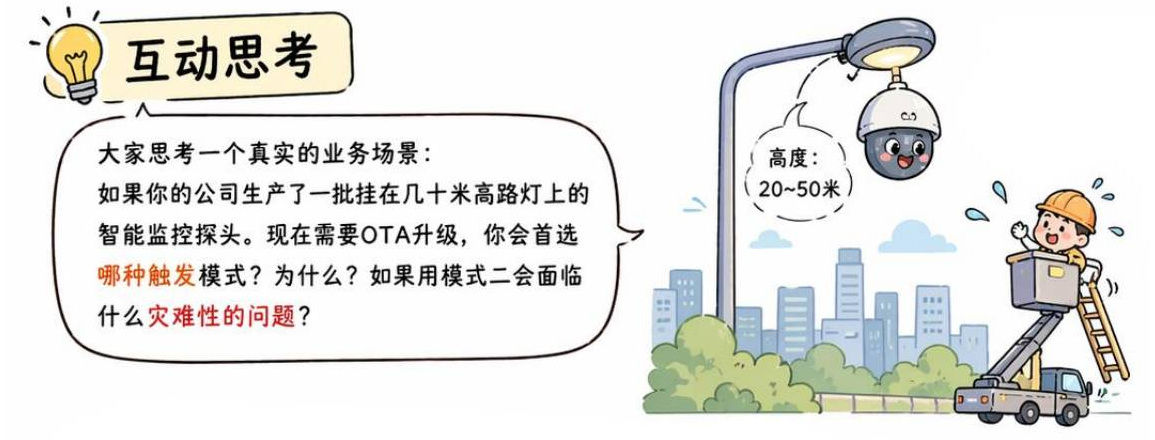

*讲义第53页：对安装在20—50米高处的设备，比较远程触发和本地维护入口的实际成本。*

**日常升级首选模式一的远程触发思路。** 设备安装位置难接近，如果每次更新都要人员到现场、连接串口或操作按键，会带来高空作业与大规模维护成本。让正常运行的 App 接收远程请求，准备升级后交给 Bootloader，才符合降低维护成本的目标。

本篇实操的传输链路仍是串口，要实现这种真实远程场景，还需要后续章节的网络连接、版本检测、固件下载与结果上报。不能把本地发送一个 `u` 就描述成已经完成 Wi-Fi 远程升级。

**模式二作为维护兜底继续保留。** 当 App 无法响应时，独立的 Bootloader 入口为现场恢复提供机会。对难接近的产品，还应评估是否需要能远程进入的恢复机制；本课的本地串口菜单本身不会消除到场操作的成本。

复习时应能独立说明：为什么需要非易失升级标志；为什么三个地址与向量偏移必须一致；倒计时与菜单各自消费哪个字节；为何“打印烧录成功”仍需检查 App 持续运行；以及两种入口如何在 Bootloader4 中共存。

下一篇进入 ESP32-C3 的 AT 固件、指令与联网，为无线升级的通信链路做准备。
